# CAP182 SS3 Part B: Applying Logistic Regression to Client Data

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_STATE = 42

## Dataset loading

Load the five data extracts then inspect their dimensions and data types and establish the target classes and imbalances.

In [2]:
DATA_DIR = Path("data")

FILE_CANDIDATES = {
    "orders": ["table1_orders_transactions.csv", "table1_orders_transactions(1).csv"],
    "customer": ["table2_customer_behaviour.csv", "table2_customer_behaviour(1).csv"],
    "returns": ["table3_return_outcomes.csv"],
    "products": ["table4_product_reference.csv"],
    "sellers": ["table5_seller_reference.csv"],}

def locate_csv(candidates):
    search_dirs = [DATA_DIR, Path("."), Path("/mnt/data")]
    for folder in search_dirs:
        for filename in candidates:
            candidate = folder / filename
            if candidate.exists():
                return candidate
    raise FileNotFoundError(
        f"Could not find any of {candidates}. Put the CSV files in ./data or beside this notebook.")

paths = {name: locate_csv(names) for name, names in FILE_CANDIDATES.items()}
data = {name: pd.read_csv(path) for name, path in paths.items()}

for name, df in data.items():
    print(f"{name.title():<10} | file={paths[name].name} | rows={len(df):,} | columns={df.shape[1]}")

orders_raw = data["orders"].copy()
customer_raw = data["customer"].copy()
returns_raw = data["returns"].copy()
products_raw = data["products"].copy()
sellers_raw = data["sellers"].copy()

print("\nRaw table dimensions:")
display(pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1], "duplicate_rows": int(df.duplicated().sum())}
                       for name, df in data.items()}).T)

print("\nTarget column preview:")
print(returns_raw["returned"].value_counts(dropna=False))

Orders     | file=table1_orders_transactions.csv | rows=17,877 | columns=16
Customer   | file=table2_customer_behaviour.csv | rows=17,842 | columns=13
Returns    | file=table3_return_outcomes.csv | rows=17,842 | columns=10
Products   | file=table4_product_reference.csv | rows=1,487 | columns=10
Sellers    | file=table5_seller_reference.csv | rows=214 | columns=5

Raw table dimensions:


,rows,columns,duplicate_rows
orders,17877,16,35
customer,17842,13,0
returns,17842,10,0
products,1487,10,0
sellers,214,5,0



Target column preview:
returned
False    14438
True      3404
Name: count, dtype: int64


### Dataset size, classes and class imbalance

The supplied Return Outcomes table contains 17,842 order instances. The target is returned, a binary label where False means the order was not returned and True means it was returned. In this extract 14,438 orders were not returned (80.92%) and 3,404 were returned (19.08%). The target appears to be quite imbalanced,thus, accuracy alone would not be an adequate evaluation measure. 

Exact duplicate order rows in the Orders/Transactions table are investigated and removed before joining, so one order contributes one modelling instance. The class proportions are recalculated after integration to confirm that no target rows were lost.

Return-outcome instances: 17,842
Not returned (False): 14,438 (80.92%)
Returned (True): 3,404 (19.08%)


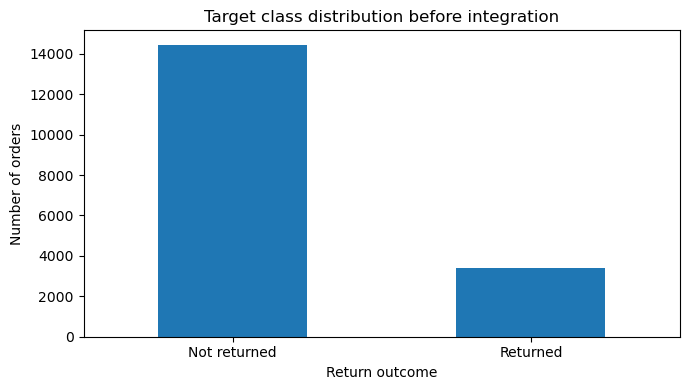


Orders table data types:


,dtype
order_id,object
customer_id,object
order_datetime,object
prd_id,object
seller_id,object
quantity,int64
unit_price,float64
discount_amount,float64
promotion_code,object
payment_method,object


In [3]:
target_counts_raw = returns_raw["returned"].value_counts(dropna=False).rename(index={False: "Not returned (False)", True: "Returned (True)"})
target_props_raw = returns_raw["returned"].value_counts(normalize=True, dropna=False)
print(f"Return-outcome instances: {len(returns_raw):,}")
for label, count in target_counts_raw.items():
    print(f"{label}: {count:,} ({count / len(returns_raw):.2%})")

fig, ax = plt.subplots(figsize=(7, 4))
plot_counts = returns_raw["returned"].map({False: "Not returned", True: "Returned"}).value_counts()
plot_counts.plot(kind="bar", ax=ax)
ax.set_title("Target class distribution before integration")
ax.set_xlabel("Return outcome")
ax.set_ylabel("Number of orders")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print("\nOrders table data types:")
display(orders_raw.dtypes.rename("dtype").to_frame())

## Preprocessing

## Model Training

## Model Validation

## Visualisations

### Comments